In [3]:
# Explicit Euler Version
import numpy as np
from scipy.sparse import coo_array

# model parameters
Du = 0.005
Dv = 0.001
k = 0.005

# spatio mesh
nx = 20
ny = 20
hx = 2.0/nx
hy = 2.0/ny
x = np.linspace(0, 2, nx+1)
y = np.linspace(0, 2, ny+1)

# time mesh
nt = 500
ht = 0.01

# initial condition w0 = (u0, v0)
w0 = np.random.randn(2*(nx+1)*(ny+1))

# store the i.c.
U0 = w0[:(nx+1)*(ny+1)].reshape(nx+1, ny+1)
V0 = w0[(nx+1)*(ny+1):].reshape(nx+1, ny+1)

# time loop
for k in range(nt):

  print(f'{k+1}/{nt}')



  # rhs vector
  b = np.zeros((2*(nx+1)*(ny+1)))

  # populate the matrix
  # internal nodes
  for i in range(1, nx):
    for j in range(1, ny):

      # enumeration
      l = i + j*(nx+1)
      lu = l
      lv = l + (nx+1)*(ny+1)

      # u_xx
      b[lu] += -2*Du*w0[lu]/(hx*hx)
      b[lu] += Du*w0[lu-1]/(hx*hx)
      b[lu] += Du*w0[lu+1]/(hx*hx)

      # u_yy
      b[lu] += -2*Du*w0[lu]/(hy*hy)
      b[lu] += Du*w0[lu-(nx+1)]/(hy*hy)
      b[lu] += Du*w0[lu+(nx+1)]/(hy*hy)

      # Ru = u - u^3 - k - v
      b[lu] += w0[lu] - w0[lu]**3 - k - w0[lv]

      # v_xx
      b[lv] += -2*Dv*w0[lv]/(hx*hx)
      b[lv] += Dv*w0[lv-1]/(hx*hx)
      b[lv] += Dv*w0[lv+1]/(hx*hx)

      # v_yy
      b[lv] += -2*Dv*w0[lv]/(hy*hy)
      b[lv] += Dv*w0[lv-(nx+1)]/(hy*hy)
      b[lv] += Dv*w0[lv+(nx+1)]/(hy*hy)

      # Rv = u - v
      b[lv] += w0[lu] - w0[lv]

    # Explicit Euler step
    w = w0 + ht*b

    # boundaries
    # y = -1
    for i in range(1, nx):
      l = i
      lu = l
      lv = l + (nx+1)*(ny+1)
      w[lu] = w[lu+nx+1]
      w[lv] = w[lv+nx+1]

    # x = 1
    for j in range(1, ny):
      l = j*(nx+1) + nx
      lu = l
      lv = l + (nx+1)*(ny+1)
      w[lu] = w[lu-1]
      w[lv] = w[lv-1]

    # y = 1
    for i in range(1, nx):
      l = ny*(nx+1) + i
      lu = l
      lv = l + (nx+1)*(ny+1)
      w[lu] = w[lu-(nx+1)]

    # x = -1
    for j in range(1, ny):
      l = j*(nx+1)
      lu = l
      lv = l + (nx+1)*(ny+1)
      w[lu] = w[lu+1]
      w[lv] = w[lv+1]

  # update c.i.
  w0 = w.copy()

# store the final solution
U = w0[:(nx+1)*(ny+1)].reshape(nx+1, ny+1)
V = w0[(nx+1)*(ny+1):].reshape(nx+1, ny+1)

1/500
2/500
3/500
4/500
5/500
6/500
7/500
8/500
9/500
10/500
11/500
12/500
13/500
14/500
15/500
16/500
17/500
18/500
19/500
20/500
21/500
22/500
23/500
24/500
25/500
26/500
27/500
28/500
29/500
30/500
31/500
32/500
33/500
34/500
35/500
36/500
37/500
38/500
39/500
40/500
41/500
42/500
43/500
44/500
45/500
46/500
47/500
48/500
49/500
50/500
51/500
52/500
53/500
54/500
55/500
56/500
57/500
58/500
59/500
60/500
61/500
62/500
63/500
64/500
65/500
66/500
67/500
68/500
69/500
70/500
71/500
72/500
73/500
74/500
75/500
76/500
77/500
78/500
79/500
80/500
81/500
82/500
83/500
84/500
85/500
86/500
87/500
88/500
89/500
90/500
91/500
92/500
93/500
94/500
95/500
96/500
97/500
98/500
99/500
100/500
101/500
102/500
103/500
104/500
105/500
106/500
107/500
108/500
109/500
110/500
111/500
112/500
113/500
114/500
115/500
116/500
117/500
118/500
119/500
120/500
121/500
122/500
123/500
124/500
125/500
126/500
127/500
128/500
129/500
130/500
131/500
132/500
133/500
134/500
135/500
136/500
137/500
138/500
139/

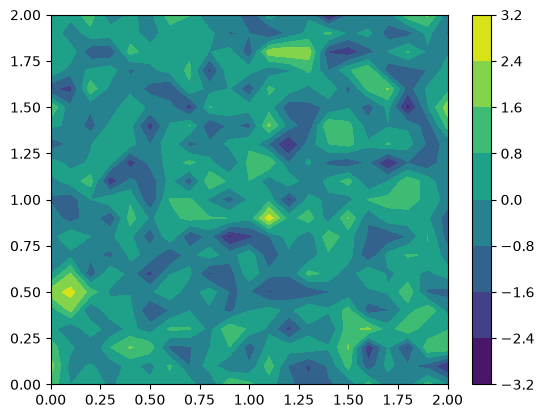

In [4]:
# vizualization
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
X, Y = np.meshgrid(x,y)
plt.contourf(X, Y, U0)
plt.colorbar()